# OpenCV - Blending

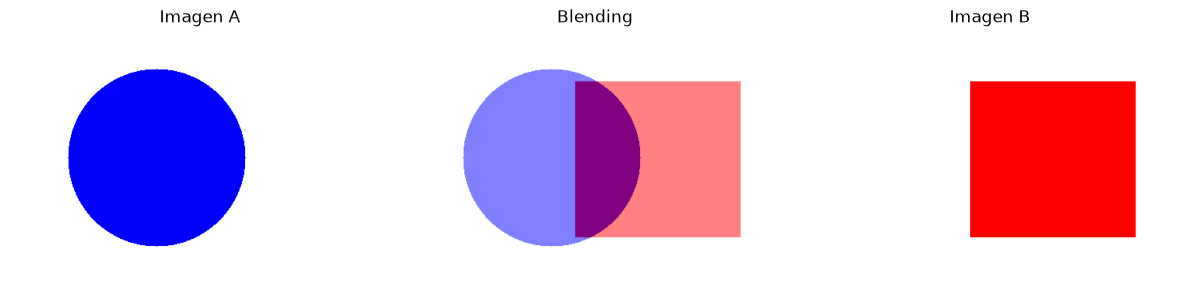

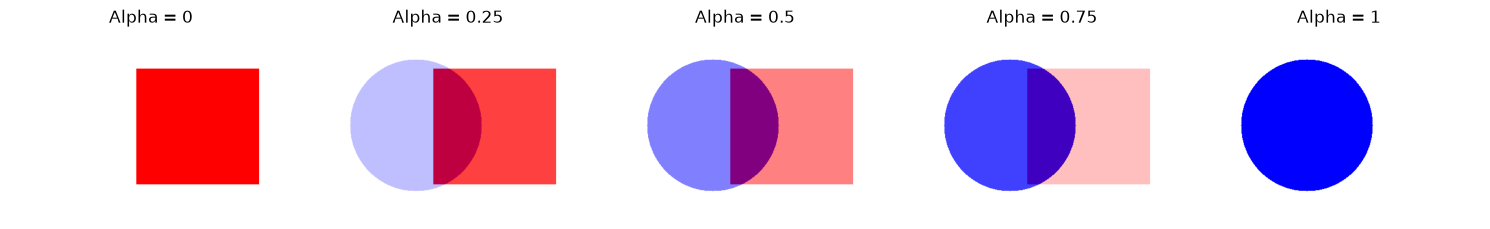

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. CREAR DOS IMÁGENES DEL MISMO TAMAÑO
# ============================================================
img1 = np.full((320, 480, 3), 255, dtype=np.uint8)
img2 = np.full_like(img1, 255)

# Dibujar un círculo azul en la primera imagen (BGR)
cv2.circle(img1, (185, 160), 112, (255, 0, 0), -1)

# Dibujar un rectángulo rojo en la segunda imagen (BGR)
cv2.rectangle(img2, (215, 64), (423, 260), (0, 0, 255), -1)

# ============================================================
# 2. APLICAR BLENDING
# ============================================================
alpha = 0.5
beta = 1 - alpha
gamma = 0

img_blend = cv2.addWeighted(img1, alpha, img2, beta, gamma)

# ============================================================
# 3. VISUALIZAR LAS IMÁGENES
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

images = [img1, img_blend, img2]
titles = ["Imagen A", "Blending", "Imagen B"]

for ax, image, title in zip(axes, images, titles):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# ============================================================
# 4. PROBAR DIFERENTES VALORES DE ALPHA
# ============================================================
fig, axes = plt.subplots(1, 5, figsize=(15, 3))

for ax, alpha in zip(axes, [0, 0.25, 0.5, 0.75, 1]):
    result = cv2.addWeighted(img1, alpha, img2, 1 - alpha, 0)
    ax.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    ax.set_title(f"Alpha = {alpha}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# OpenCV - Deteccion de bordes

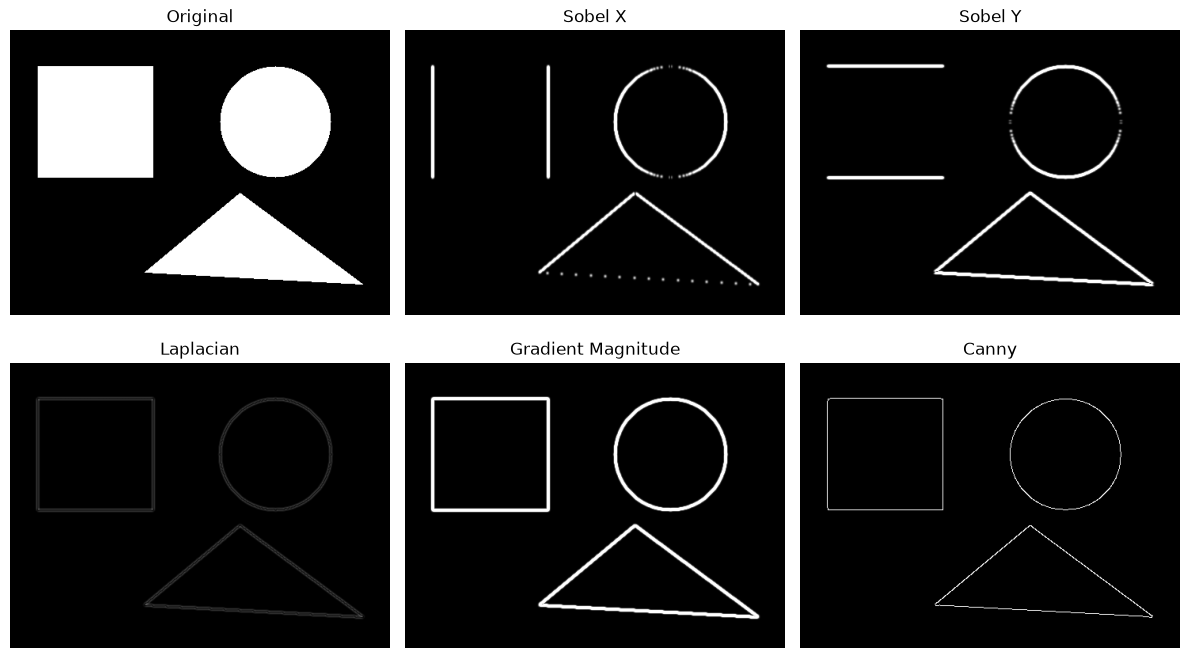

In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. CREAR IMAGEN CON FIGURAS GEOMÉTRICAS
# ============================================================
img = np.zeros((360, 480), dtype=np.uint8)

# Rectángulo blanco
cv2.rectangle(img, (35, 45), (180, 185), 255, -1)

# Círculo blanco
cv2.circle(img, (335, 115), 70, 255, -1)

# Triángulo blanco
points = np.array([
    [170, 305],
    [290, 205],
    [445, 320]
], dtype=np.int32)

cv2.fillPoly(img, [points], 255)

# ============================================================
# 2. REDUCIR EL RUIDO CON GAUSSIAN BLUR
# ============================================================
blurred = cv2.GaussianBlur(img, (5, 5), 0)

# ============================================================
# 3. APLICAR SOBEL X Y SOBEL Y
# ============================================================
sobel_x = cv2.Sobel(
    blurred, cv2.CV_64F, 1, 0, ksize=3
)

sobel_y = cv2.Sobel(
    blurred, cv2.CV_64F, 0, 1, ksize=3
)

# ============================================================
# 4. APLICAR LAPLACIAN
# ============================================================
laplacian = cv2.Laplacian(
    blurred, cv2.CV_64F
)

# ============================================================
# 5. CALCULAR MAGNITUD DEL GRADIENTE
# ============================================================
magnitude = cv2.magnitude(sobel_x, sobel_y)

# ============================================================
# 6. APLICAR CANNY
# ============================================================
canny = cv2.Canny(
    blurred,
    threshold1=80,
    threshold2=160
)

# ============================================================
# 7. CONVERTIR RESULTADOS PARA VISUALIZACIÓN
# ============================================================
sobel_x_view = cv2.convertScaleAbs(sobel_x)
sobel_y_view = cv2.convertScaleAbs(sobel_y)
laplacian_view = cv2.convertScaleAbs(laplacian)
magnitude_view = cv2.convertScaleAbs(magnitude)

# ============================================================
# 8. MOSTRAR RESULTADOS
# ============================================================
images = [
    img,
    sobel_x_view,
    sobel_y_view,
    laplacian_view,
    magnitude_view,
    canny
]

titles = [
    "Original",
    "Sobel X",
    "Sobel Y",
    "Laplacian",
    "Gradient Magnitude",
    "Canny"
]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, image, title in zip(axes.flat, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()